# Chapitre 6 - Exercices 6.7 à 6.12

Ce notebook traite six exercices sur l'optimisation du RAG, les agents et la mémoire :

- **6.7** : reranking sous budget de latence (combien de candidats donner au cross-encoder ?) ;
- **6.8** : réécriture de requête dans une conversation qui change de sujet (mini-lab) ;
- **6.9** : erreurs composées et réflexion : calcul, simulation de Monte-Carlo, coût ;
- **6.10** : valider des appels de fonctions et mesurer l'effet des descriptions d'outils ;
- **6.11** : planification : ordre des filtres, dépendances entre actions, parallélisme ;
- **6.12** : mémoire : budget de contexte et éviction selon la position d'un fait.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import json
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 100)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
Q = c6.QUESTIONS
bm25 = c6.TermRetriever(TEXTS, IDS)
dense = c6.DenseRetriever(TEXTS, IDS)

## Exercice 6.7 : Reranking sous budget de latence

**Énoncé.** On reclasse les $N$ premiers candidats de la recherche hybride avec le
cross-encoder `bge-reranker-v2-m3` (≈ 568 M paramètres).

1. Estimer le coût de calcul d'une paire (question, passage) d'environ 120 tokens, et en
   déduire un ordre de grandeur de la latence pour $N = 20$ sur un GPU qui soutient
   effectivement 20 TFLOP/s.
2. Mesurer la latence réelle et le MRR en fonction de $N \in \{1, 3, 5, 10, 20, 40, 64\}$.
3. Avec un budget de 150 ms par requête pour le reranking, quel $N$ choisir ?

**Rappels.** Section *Reranking* et cours 2 : un cross-encoder lit chaque paire en entier ;
son coût est proportionnel au nombre de candidats. Un passage avant (*forward*) d'un
transformeur coûte environ $2 \times (\text{paramètres}) \times (\text{tokens})$ FLOP.

**Solution.**

1. $2 \times 5{,}68\cdot10^8 \times 120 \approx 1{,}4 \cdot 10^{11}$ FLOP par paire (une partie
   des paramètres sont des embeddings de vocabulaire, peu coûteux : c'est une majoration). Pour
   $N = 20$ : $2{,}7 \cdot 10^{12}$ FLOP, soit environ 140 ms à 20 TFLOP/s. Le calcul étant
   linéaire en $N$, la latence l'est aussi (en plus d'un coût fixe de lancement).
2. Voir la mesure ci-dessous.
3. Le plus petit $N$ qui atteint le plateau de MRR sous le budget. $\blacksquare$

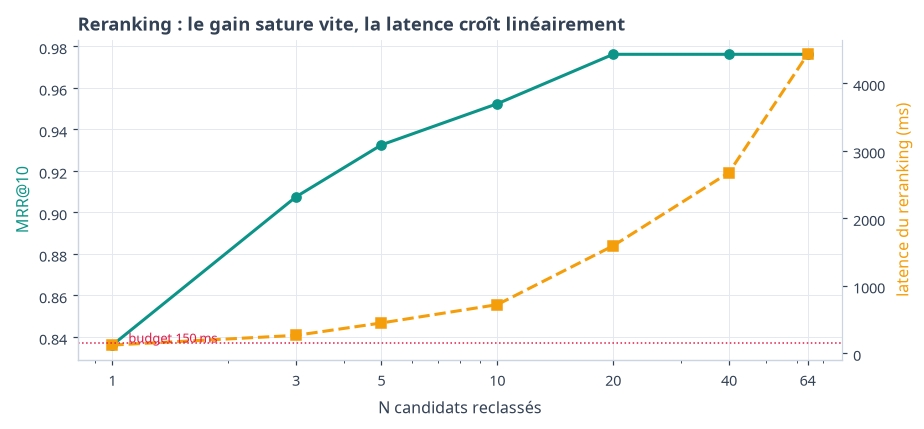

,N,MRR@10,latence (ms)
0,1,0.836,119.236
1,3,0.908,262.723
2,5,0.933,446.593
3,10,0.952,717.794
4,20,0.976,1589.890
5,40,0.976,2675.683
6,64,0.976,4427.184


In [2]:
hyb = {q["qid"]: [d_ for d_, _ in c6.rrf([bm25.search(q["question"], 64), dense.search(q["question"], 64)])] for q in Q}
ce_all = {q["qid"]: dict(zip(IDS, c6.cross_encoder_scores(q["question"], TEXTS))) for q in Q}  # tous les scores, une fois
Ns = [1, 3, 5, 10, 20, 40, 64]
mrr, lat = [], []
for N in Ns:
    run = {}
    for q in Q:
        cand = hyb[q["qid"]][:N]
        run[q["qid"]] = sorted(cand, key=lambda d_: -ce_all[q["qid"]][d_]) + [d_ for d_ in hyb[q["qid"]] if d_ not in cand]
    mrr.append(c6.evaluate(run, k=10)["MRR"])
    t0 = time.perf_counter()
    for q in Q[:12]:
        c6.cross_encoder_scores(q["question"], [TXT[d_] for d_ in hyb[q["qid"]][:N]])
    lat.append((time.perf_counter() - t0) / 12 * 1000)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(Ns, mrr, marker="o", color=TEAL); ax.set_ylabel("MRR@10", color=TEAL); ax.set_xlabel("N candidats reclassés")
ax.set_xscale("log"); ax.set_xticks(Ns); ax.set_xticklabels(Ns)
ax2 = ax.twinx(); ax2.plot(Ns, lat, marker="s", ls="--", color=AMBER); ax2.set_ylabel("latence du reranking (ms)", color=AMBER)
ax2.axhline(150, color=ROSE, lw=1, ls=":"); ax2.text(1.1, 155, "budget 150 ms", color=ROSE, fontsize=8.5)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_title("Reranking : le gain sature vite, la latence croît linéairement")
plt.tight_layout(); plt.show()
pd.DataFrame({"N": Ns, "MRR@10": mrr, "latence (ms)": lat}).round(3)

**Vérification.** La latence mesurée croît à peu près linéairement avec $N$, avec un coût fixe
(lancement des noyaux GPU, tokenisation) visible pour les petits $N$ ; l'ordre de grandeur
calculé est le bon, le GPU traitant les paires en lot. Le MRR, lui, sature dès que le bon
passage figure parmi les candidats : la recherche hybride le place presque toujours dans les
10 premiers, donc reclasser au-delà n'apporte plus rien. On choisit le plus petit $N$ du plateau
qui respecte le budget (ici, de l'ordre de 10 à 20).

> **À retenir.** Le coût d'un reranker est linéaire en $N$ ; son gain sature quand le rappel
> du premier étage sature. On dimensionne $N$ avec la courbe rappel@N du retriever et la
> latence mesurée du reranker.

## Exercice 6.8 : Réécriture dans une conversation qui change de sujet

**Énoncé.** On reprend les 8 conversations du cours 2, mais on insère entre l'échange initial
et la question de suivi un échange **hors sujet** (« Au fait, quelle heure est-il à Tokyo ? »).
Comparer, en Hit@3 de la recherche hybride : (a) la question brute, (b) la question précédée du
**dernier** message utilisateur, (c) la question précédée de **tout** l'historique utilisateur,
(d) une réécriture par Qwen2.5-1.5B (sur CPU) qui voit tout l'historique.
Expliquer les résultats.

**Rappels.** Section *Query rewriting* : la requête réécrite doit avoir du sens seule. Une
heuristique sans modèle (concaténer le message précédent) marchait bien sur les conversations
courtes du cours 2.

**Solution (raisonnement).** (b) concatène le message hors sujet : il échoue dès que le sujet a
changé. (c) récupère l'entité, mais noie la requête dans des mots sans rapport, ce qui peut
égarer BM25 comme les embeddings. (d) peut **sélectionner** dans l'historique l'entité à laquelle
renvoie le pronom : c'est exactement la tâche de résolution de référence qu'un modèle de
langage sait faire, s'il est assez capable.

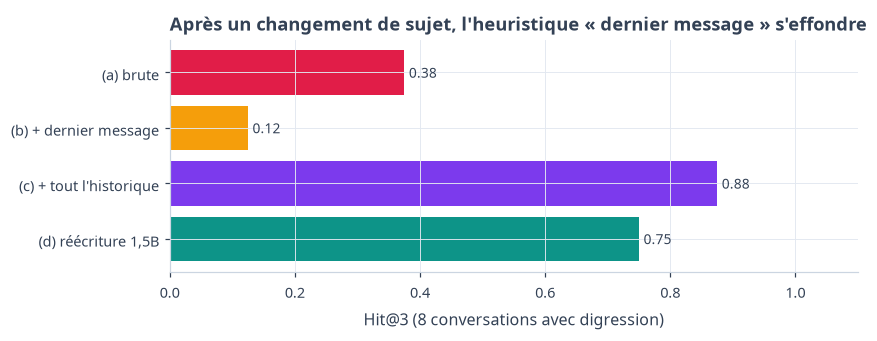

,question,"réécriture 1,5B"
0,Peut-on la renouveler ?,Peut-on prolonger la période d'essai chez Calypso ?
1,Quelle est sa particularité la plus célèbre ?,Quelle est la particularité la plus célèbre de Jupiter ?
2,Comment savoir quel programme est en cause ?,Comment détecter le processus en cause ?
3,Et quelles herbes ajoute-t-on à la fin ?,Et quelle sauce ajoute-on à la fin ?
4,Et à partir de quand y a-t-on droit ?,Et à partir de combien de jours par semaine y a-t-on droit ?
5,Je peux le rendre s'il ne va pas à mon chat ?,Peux-tu me donner son adresse si il n'est pas au travail ?
6,À quelle distance faut-il les espacer ?,À quelle distance faut-il les espacer entre les tomates ?
7,Combien de temps est-il couvert en cas de panne ?,Quel temps est couvert en cas de panne du thermostat Thermo-X200 ?


In [3]:
HORS_SUJET = [("user", "Au fait, quelle heure est-il à Tokyo en ce moment ?"),
              ("assistant", "Il y a huit heures de décalage avec Paris en hiver.")]
convs = [dict(c, history=c["history"] + HORS_SUJET) for c in c6.CONVERSATIONS]
SYS = ("Tu reformules des questions. Tu ne réponds jamais à la question : tu la réécris pour qu'elle soit compréhensible "
       "seule, en remplaçant les pronoms (il, elle, la, les, sa, ça) par le nom qu'ils désignent dans la conversation.")
EX = [("Utilisateur : Quelle est la capitale de l'Italie ?\nAssistant : Rome.\nUtilisateur : Tu aimes la pizza ?\nAssistant : Oui !",
       "Combien d'habitants a-t-elle ?", "Combien d'habitants a Rome ?")]
fmt = lambda h: "\n".join(("Utilisateur : " if r == "user" else "Assistant : ") + m for r, m in h)  # noqa: E731

def msgs(c):
    m = [{"role": "system", "content": SYS}]
    for h, f, rep in EX:
        m += [{"role": "user", "content": f"Conversation :\n{h}\nQuestion à réécrire : {f}"}, {"role": "assistant", "content": rep}]
    return m + [{"role": "user", "content": f"Conversation :\n{fmt(c['history'])}\nQuestion à réécrire : {c['followup']}"}]

rw15 = [r.split("\n")[0].strip() for r in c6.generate_batch([msgs(c) for c in convs], model_id=llm.MEDIUM, max_new_tokens=40, device="cpu")]

def hit3(query, rel):
    top = [d_ for d_, _ in c6.rrf([bm25.search(query, 10), dense.search(query, 10)])][:3]
    return float(any(t in rel for t in top))

rows = []
for c, rw in zip(convs, rw15):
    users = [m for r, m in c["history"] if r == "user"]
    rows.append({"question": c["followup"], "réécriture 1,5B": rw,
                 "(a) brute": hit3(c["followup"], c["relevant"]),
                 "(b) + dernier message": hit3(users[-1] + " " + c["followup"], c["relevant"]),
                 "(c) + tout l'historique": hit3(" ".join(users) + " " + c["followup"], c["relevant"]),
                 "(d) réécriture 1,5B": hit3(rw, c["relevant"])})
df68 = pd.DataFrame(rows)
sc = df68.iloc[:, 2:].mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(sc.index[::-1], sc.values[::-1], color=[TEAL, VIOLET, AMBER, ROSE]); annotate_bars(ax, "{:.2f}")
ax.set_xlim(0, 1.1); ax.set_xlabel("Hit@3 (8 conversations avec digression)")
ax.set_title("Après un changement de sujet, l'heuristique « dernier message » s'effondre")
plt.tight_layout(); plt.show()
df68[["question", "réécriture 1,5B"]]

**Vérification.** L'heuristique du dernier message s'effondre, sous le niveau de la question
brute : elle ajoute la digression, qui égare la recherche. Concaténer **tout** l'historique
utilisateur est ici le meilleur choix : avec deux messages seulement, le bruit reste faible et
la recherche hybride retrouve l'entité. La réécriture par Qwen2.5-1,5B résout la plupart des
références, mais lisez ses sorties : certaines déforment la question (« sauce » au lieu d'«
herbes », une question sur une adresse au lieu d'un retour d'article). Sur de longues
conversations, la concaténation intégrale grossit sans limite et se dilue ; un réécrivain plus
capable devient alors indispensable.

> **À retenir.** Les heuristiques de concaténation sont fragiles dès que la conversation
> dévie ; la réécriture par un modèle (suffisamment capable) sélectionne la bonne référence.
> Toujours évaluer la réécriture **par la qualité de la recherche** qu'elle produit.

## Exercice 6.9 : Erreurs composées et réflexion

**Énoncé.** Un agent exécute une tâche de $n$ étapes ; chaque étape réussit avec probabilité
$p = 0{,}95$, indépendamment. On ajoute un **vérificateur** qui détecte une étape ratée avec
probabilité (rappel) $r = 0{,}8$ ; une étape détectée comme ratée est refaite une fois, et la
reprise réussit avec probabilité $q = 0{,}7$.

1. Probabilité de succès d'une étape avec vérification, puis de la tâche, pour $n = 10$ et
   $n = 50$.
2. Nombre maximal d'étapes pour garder 50 % de réussite, avec et sans vérificateur.
3. Nombre moyen d'appels au modèle par étape (coût de la réflexion), en supposant que le
   vérificateur ne déclenche pas de fausse alerte.
4. Vérifier par simulation de Monte-Carlo.

**Rappels.** Section *Agent Overview* : la précision globale chute avec le nombre d'étapes
($p^n$). Section *Reflection and error correction* : évaluer puis corriger améliore le succès,
au prix de latence et de coût.

**Solution.**

1. Une étape réussit si elle réussit du premier coup, ou si elle échoue, est détectée et la
   reprise réussit : $p' = p + (1 - p)\,r\,q = 0{,}95 + 0{,}05 \times 0{,}8 \times 0{,}7 = 0{,}978$.
   Tâche : $p^{10} = 0{,}599$ contre $p'^{10} = 0{,}800$ ; $p^{50} = 0{,}077$ contre
   $p'^{50} = 0{,}329$.
2. $n_{\max} = \lfloor \ln 0{,}5 / \ln p \rfloor$ : 13 étapes sans vérificateur, 31 avec.
3. Appels par étape : $1 + (1 - p)\,r = 1{,}04$ (plus l'appel au vérificateur lui-même s'il est
   un modèle : $2{,}04$). La réflexion coûte peu ici, car les reprises sont rares.
4. Voir la simulation. $\blacksquare$

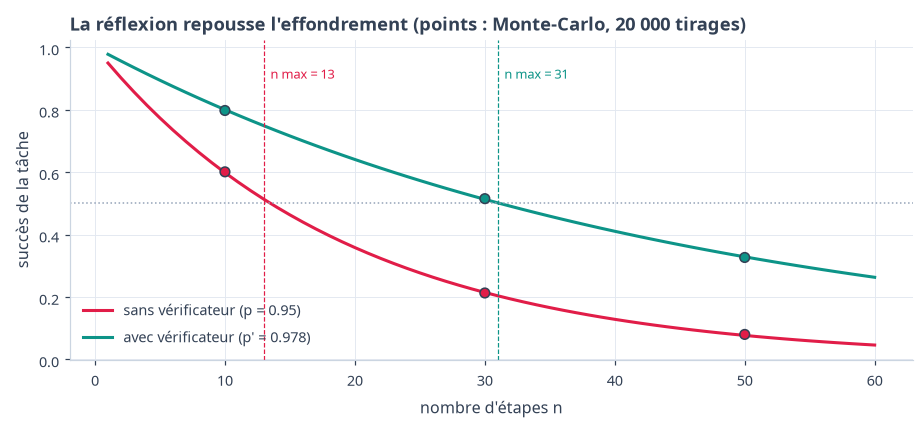

p' = 0.978 ; n = 10 : 0.599 -> 0.801 ; n = 50 : 0.077 -> 0.329 ; appels par étape : 1.040


In [4]:
p, r, q_ = 0.95, 0.8, 0.7
p2 = p + (1 - p) * r * q_
rng = np.random.default_rng(0)

def simule(n, verif, n_sim=20000):
    ok = rng.random((n_sim, n)) < p
    if verif:
        retry = (~ok) & (rng.random((n_sim, n)) < r)
        ok = ok | (retry & (rng.random((n_sim, n)) < q_))
    return ok.all(axis=1).mean()

ns = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(ns, p ** ns, color=ROSE, label=f"sans vérificateur (p = {p})")
ax.plot(ns, p2 ** ns, color=TEAL, label=f"avec vérificateur (p' = {p2:.3f})")
for n_, col in [(10, None), (30, None), (50, None)]:
    ax.scatter([n_, n_], [simule(n_, False), simule(n_, True)], color=[ROSE, TEAL], edgecolor=SLATE, zorder=5, s=40)
ax.axhline(0.5, color=GRAY, ls=":", lw=1)
nmax = [int(np.floor(np.log(0.5) / np.log(x))) for x in (p, p2)]
for nm, col in zip(nmax, [ROSE, TEAL]):
    ax.axvline(nm, color=col, ls="--", lw=0.8); ax.text(nm + 0.5, 0.9, f"n max = {nm}", color=col, fontsize=8.5)
ax.set_xlabel("nombre d'étapes n"); ax.set_ylabel("succès de la tâche"); ax.legend(loc="lower left")
ax.set_title("La réflexion repousse l'effondrement (points : Monte-Carlo, 20 000 tirages)")
plt.tight_layout(); plt.show()
print(f"p' = {p2:.3f} ; n = 10 : {p ** 10:.3f} -> {p2 ** 10:.3f} ; n = 50 : {p ** 50:.3f} -> {p2 ** 50:.3f} ; "
      f"appels par étape : {1 + (1 - p) * r:.3f}")

> **À retenir.** Un vérificateur de rappel $r$ et une reprise de succès $q$ transforment $p$
> en $p + (1-p)\,r\,q$ : un petit gain par étape devient un gros gain sur une longue tâche,
> pour un surcoût proportionnel au taux d'échec.